<a href="https://colab.research.google.com/github/JSEFERINO/Archivos-DOE-2026/blob/main/Disenos_Factoriales_Fraccionados_DOE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diseños Factoriales Fraccionados $2^{k-p}$
## Caso de Estudio: Reducción de la Vibración en Equipo de Afilado · Simulacro Saber Pro

**Estudiante:** DANIEL ANDRES ARIAS LOPEZ  
**ID Institucional:** T00062604  
**Correo:** darlopez2003@gmail.com  
**Asignatura:** Diseño y Análisis de Experimentos (DOE)  

---
### Descripción del Proyecto
Este notebook reproduce de forma interactiva y reproducible el análisis estadístico completo para el experimento de vibración en una máquina de afilado utilizando un **diseño factorial fraccionado $2^{7-4}$ de Resolución III (8 corridas)**.

Incluye:
1. **Carga y estructuración** de los datos experimentales y niveles de factores.
2. **Estimación analítica de efectos**, contrastes y Sumas de Cuadrados con `numpy` y `scipy`.
3. **Tabla ANOVA del Mejor Modelo** con $R^2_{\text{ajustado}} = 93.71\%$.
4. **Estructura de alias reducida** del diseño fraccionado $2^{7-4}$.
5. **Figura 1:** Diagrama de Pareto de Efectos Estandarizados.
6. **Figura 2:** Gráfico de Probabilidad Normal de Efectos (Gráfico de Daniel).
7. **Figura 3:** Gráficas de Efectos Principales Significativos ($A$, $C$ y $E$).
8. **Figura 4:** Gráfico de Cubo de Superficie de Respuesta y Condición Óptima ($40.55$ mín).
9. **Matriz resumen** con las respuestas justificadas a las 30 preguntas del formulario.

## 1. Configuración de Entorno e Importación de Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Configuración de estilo visual profesional
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
print('Librerías cargadas exitosamente.')

Librerías cargadas exitosamente.


## 2. Definición de Factores y Matriz de Diseño Experimental

In [ ]:
# Tabla 1: Factores de control y sus niveles (codificados y naturales)
df_factores = pd.DataFrame({
    'Factor': ['A', 'B', 'C', 'D', 'E', 'F', 'G'],
    'Variable': [
        'Tamaño de grano',
        'Longitud de la herramienta',
        'Diámetro de la herramienta',
        'Velocidad del husillo (RPM)',
        'Peso de precarga',
        'Estructura del material',
        'Velocidad de alimentación'
    ],
    'Unidades': ['mallas/pulg', 'pulg', 'pulg', 'x1000 rpm', 'lb', 'oz', 'pulg/min'],
    'Nivel_Bajo_(-1)': [80, 1.0, 1.0, 15, 1.0, 1.0, 2.0],
    'Nivel_Alto_(+1)': [120, 2.0, 1.5, 20, 4.0, 4.0, 4.0]
})

print('--- Tabla 1: Factores de Control del Experimento ---')
df_factores

--- Tabla 1: Factores de Control del Experimento ---


,Factor,Variable,Unidades,Nivel_Bajo_(-1),Nivel_Alto_(+1)
0,A,Tamaño de grano,mallas/pulg,80.0,120.0
1,B,Longitud de la herramienta,pulg,1.0,2.0
2,C,Diámetro de la herramienta,pulg,1.0,1.5
3,D,Velocidad del husillo (RPM),x1000 rpm,15.0,20.0
4,E,Peso de precarga,lb,1.0,4.0
5,F,Estructura del material,oz,1.0,4.0
6,G,Velocidad de alimentación,pulg/min,2.0,4.0


In [ ]:
# Tabla 2: Matriz de diseño fraccionado 2^(7-4) y respuesta observada de vibración (Y)
data_exp = {
    'Corrida': [1, 2, 3, 4, 5, 6, 7, 8],
    'A': [-1.0,  1.0, -1.0,  1.0, -1.0,  1.0, -1.0,  1.0],
    'B': [-1.0, -1.0,  1.0,  1.0, -1.0, -1.0,  1.0,  1.0],
    'C': [-1.0, -1.0, -1.0, -1.0,  1.0,  1.0,  1.0,  1.0],
    'D': [ 1.0, -1.0, -1.0,  1.0,  1.0, -1.0, -1.0,  1.0],  # D = AB
    'E': [ 1.0, -1.0,  1.0, -1.0, -1.0,  1.0, -1.0,  1.0],  # E = AC
    'F': [ 1.0,  1.0, -1.0, -1.0, -1.0, -1.0,  1.0,  1.0],  # F = BC
    'G': [-1.0,  1.0,  1.0, -1.0,  1.0, -1.0, -1.0,  1.0],  # G = ABC
    'Vibracion_Y': [77.4, 68.3, 81.9, 66.2, 42.1, 78.3, 39.0, 68.4]
}

df_diseno = pd.DataFrame(data_exp)
print('--- Tabla 2: Matriz de Diseño 2^(7-4) y Vibración Observada ---')
df_diseno

--- Tabla 2: Matriz de Diseño 2^(7-4) y Vibración Observada ---


,Corrida,A,B,C,D,E,F,G,Vibracion_Y
0,1,-1.0,-1.0,-1.0,1.0,1.0,1.0,-1.0,77.4
1,2,1.0,-1.0,-1.0,-1.0,-1.0,1.0,1.0,68.3
2,3,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,81.9
3,4,1.0,1.0,-1.0,1.0,-1.0,-1.0,-1.0,66.2
4,5,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0,42.1
5,6,1.0,-1.0,1.0,-1.0,1.0,-1.0,-1.0,78.3
6,7,-1.0,1.0,1.0,-1.0,-1.0,1.0,-1.0,39.0
7,8,1.0,1.0,1.0,1.0,1.0,1.0,1.0,68.4


## 3. Estimación de Efectos y Tabla ANOVA del Mejor Modelo

In [ ]:
# Estimación matemática de contrastes, efectos factoriales y Sumas de Cuadrados (SC)
factors = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Y = df_diseno['Vibracion_Y'].values
N = len(Y)

results = []
for f in factors:
    col = df_diseno[f].values
    contrast = np.dot(col, Y)
    effect = contrast / (N / 2)   # Efecto = Contraste / 4
    sc = (contrast ** 2) / N      # SC = Contraste^2 / 8
    results.append({'Factor': f, 'Contraste': contrast, 'Efecto': effect, 'SC': sc})

df_effects = pd.DataFrame(results)
print('--- Resumen de Contrastes y Sumas de Cuadrados ---')
df_effects

--- Resumen de Contrastes y Sumas de Cuadrados ---


,Factor,Contraste,Efecto,SC
0,A,40.8,10.20,208.080
1,B,-10.6,-2.65,14.045
2,C,-66.0,-16.50,544.500
3,D,-13.4,-3.35,22.445
4,E,90.4,22.60,1021.520
5,F,-15.4,-3.85,29.645
6,G,-0.2,-0.05,0.005


In [ ]:
# Cálculo formal del ANOVA para el Mejor Modelo (A, C, E)
y_mean = np.mean(Y)
sc_total = np.sum((Y - y_mean) ** 2)

sc_A = df_effects.loc[df_effects['Factor'] == 'A', 'SC'].values[0]
sc_C = df_effects.loc[df_effects['Factor'] == 'C', 'SC'].values[0]
sc_E = df_effects.loc[df_effects['Factor'] == 'E', 'SC'].values[0]
sc_model = sc_A + sc_C + sc_E
sc_error = sc_total - sc_model  # Suma de B, D, F, G

gl_A, gl_C, gl_E = 1, 1, 1
gl_error = 4  # 7 GL totales - 3 GL modelo
gl_total = 7

cm_A = sc_A / gl_A
cm_C = sc_C / gl_C
cm_E = sc_E / gl_E
cm_error = sc_error / gl_error

f0_A = cm_A / cm_error
f0_C = cm_C / cm_error
f0_E = cm_E / cm_error

p_A = 1 - stats.f.cdf(f0_A, dfn=1, dfd=gl_error)
p_C = 1 - stats.f.cdf(f0_C, dfn=1, dfd=gl_error)
p_E = 1 - stats.f.cdf(f0_E, dfn=1, dfd=gl_error)

r2 = (sc_model / sc_total) * 100
r2_adj = (1 - (cm_error / (sc_total / gl_total))) * 100

df_anova = pd.DataFrame({
    'Fuente de Variación': ['A: Grano', 'C: Diámetro', 'E: Peso precarga', 'Error Residual (B, D, F, G)', 'Total'],
    'SC': [sc_A, sc_C, sc_E, sc_error, sc_total],
    'G.L.': [gl_A, gl_C, gl_E, gl_error, gl_total],
    'C.M.': [cm_A, cm_C, cm_E, cm_error, np.nan],
    'F0': [f0_A, f0_C, f0_E, np.nan, np.nan],
    'Valor-p': [p_A, p_C, p_E, np.nan, np.nan],
    'Conclusión (alpha = 0.05)': [
        'Significativo (p < 0.05)',
        'Significativo (p < 0.01)',
        'Significativo (p < 0.005)',
        'Efectos no significativos agrupados',
        f'R^2 = {r2:.2f}%, R^2 ajustado = {r2_adj:.2f}%'
    ]
})

print('=== TABLA ANOVA DEL MEJOR MODELO ===')
display(df_anova.round({'SC': 2, 'C.M.': 3, 'F0': 2, 'Valor-p': 4}))
print(f'R^2 = {r2:.2f}%')
print(f'R^2 ajustado = {r2_adj:.2f}%')

# Coeficientes del modelo de regresión en variables codificadas (-1, +1)
beta_0 = y_mean
beta_A = df_effects.loc[df_effects['Factor'] == 'A', 'Efecto'].values[0] / 2
beta_C = df_effects.loc[df_effects['Factor'] == 'C', 'Efecto'].values[0] / 2
beta_E = df_effects.loc[df_effects['Factor'] == 'E', 'Efecto'].values[0] / 2
print(f'Modelo ajustado: Y_hat = {beta_0:.2f} + ({beta_A:.2f})*A + ({beta_C:.2f})*C + ({beta_E:.2f})*E')

=== TABLA ANOVA DEL MEJOR MODELO ===


,Fuente de Variación,SC,G.L.,C.M.,F0,Valor-p,Conclusión (alpha = 0.05)
0,A: Grano,208.08,1,208.080,12.58,0.0239,Significativo (p < 0.05)
1,C: Diámetro,544.50,1,544.500,32.93,0.0046,Significativo (p < 0.01)
2,E: Peso precarga,1021.52,1,1021.520,61.78,0.0014,Significativo (p < 0.005)
3,"Error Residual (B, D, F, G)",66.14,4,16.535,NaN,NaN,Efectos no significativos agrupados
4,Total,1840.24,7,NaN,NaN,NaN,"R^2 = 96.41%, R^2 ajustado = 93.71%"


R^2 = 96.41%
R^2 ajustado = 93.71%
Modelo ajustado: Y_hat = 65.20 + (5.10)*A + (-8.25)*C + (11.30)*E


## 4. Estructura de Alias Reducida del Diseño $2^{7-4}_{\text{III}}$

In [ ]:
df_alias = pd.DataFrame({
    'Efecto Principal': ['[A]', '[B]', '[C]', '[D]', '[E]', '[F]', '[G]'],
    'Estructura de Alias Reducida': [
        'A + BD + CE + FG',
        'B + AD + CF + EG',
        'C + AE + BF + DG',
        'D + AB + CG + EF',
        'E + AC + BG + DF',
        'F + AG + BC + DE',
        'G + AF + BE + CD'
    ],
    'Resolución': ['III'] * 7,
    'Interpretación Técnica': [
        'Confundido con interacciones dobles BD, CE, FG',
        'Confundido con interacciones dobles AD, CF, EG',
        'Confundido con interacciones dobles AE, BF, DG',
        'Confundido con interacciones dobles AB, CG, EF',
        'Confundido con interacciones dobles AC, BG, DF',
        'Confundido con interacciones dobles AG, BC, DE',
        'Confundido con interacciones dobles AF, BE, CD'
    ]
})
print('--- Tabla 3: Estructura de Alias del Diseño 2^(7-4) ---')
df_alias

--- Tabla 3: Estructura de Alias del Diseño 2^(7-4) ---


,Efecto Principal,Estructura de Alias Reducida,Resolución,Interpretación Técnica
0,[A],A + BD + CE + FG,III,"Confundido con interacciones dobles BD, CE, FG"
1,[B],B + AD + CF + EG,III,"Confundido con interacciones dobles AD, CF, EG"
2,[C],C + AE + BF + DG,III,"Confundido con interacciones dobles AE, BF, DG"
3,[D],D + AB + CG + EF,III,"Confundido con interacciones dobles AB, CG, EF"
4,[E],E + AC + BG + DF,III,"Confundido con interacciones dobles AC, BG, DF"
5,[F],F + AG + BC + DE,III,"Confundido con interacciones dobles AG, BC, DE"
6,[G],G + AF + BE + CD,III,"Confundido con interacciones dobles AF, BE, CD"


## 5. Visualización 1: Diagrama de Pareto de Efectos Estandarizados

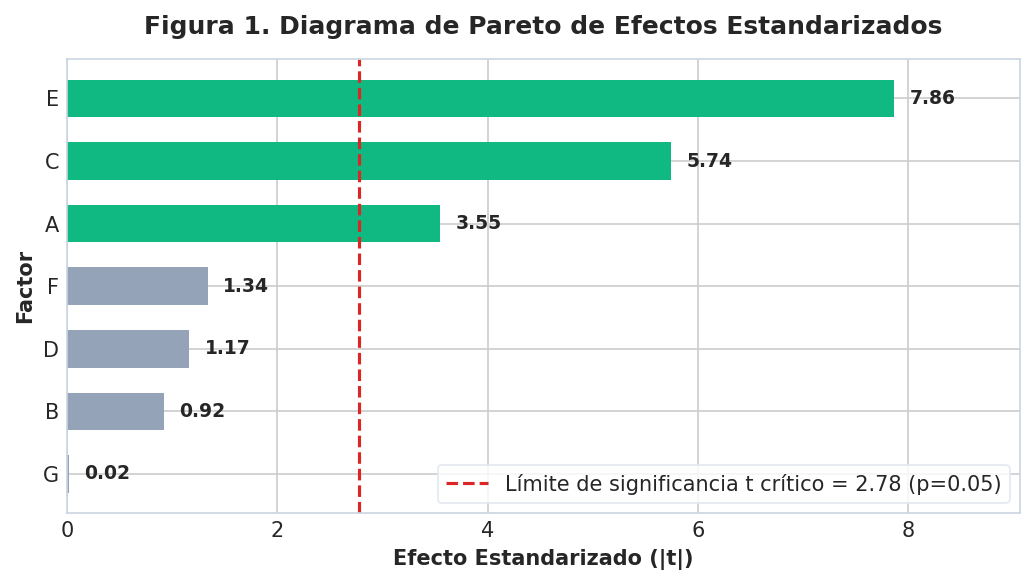

In [ ]:
# t estandarizado = |Efecto| / SE(Efecto)
# SE(Efecto) = sqrt(MSE / (N / 4)) = sqrt(16.535 / 2) = 2.875
se_effect = np.sqrt(cm_error / 2)
t_vals = np.abs(df_effects['Efecto'].values) / se_effect
df_pareto = pd.DataFrame({'Factor': df_effects['Factor'], 't_stat': t_vals}).sort_values('t_stat')

# Umbral crítico t con alpha=0.05 y 4 grados de libertad del error
t_crit = stats.t.ppf(1 - 0.05/2, df=gl_error)  # t_crit = 2.776

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
colors = ['#10b981' if t >= t_crit else '#94a3b8' for t in df_pareto['t_stat']]
bars = ax.barh(df_pareto['Factor'], df_pareto['t_stat'], color=colors, height=0.6)
ax.axvline(x=t_crit, color='#dc2626', linestyle='--', linewidth=1.5, label=f'Límite de significancia t crítico = {t_crit:.2f} (p=0.05)')

for bar in bars:
    val = bar.get_width()
    ax.text(val + 0.15, bar.get_y() + bar.get_height()/2, f'{val:.2f}', va='center', fontsize=9, fontweight='bold')

ax.set_xlabel('Efecto Estandarizado (|t|)', fontsize=10, fontweight='bold')
ax.set_ylabel('Factor', fontsize=10, fontweight='bold')
ax.set_title('Figura 1. Diagrama de Pareto de Efectos Estandarizados', fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#e2e8f0')
ax.set_xlim(0, max(df_pareto['t_stat']) + 1.2)
plt.tight_layout()
plt.show()

## 6. Visualización 2: Gráfico de Probabilidad Normal de Efectos (Gráfico de Daniel)

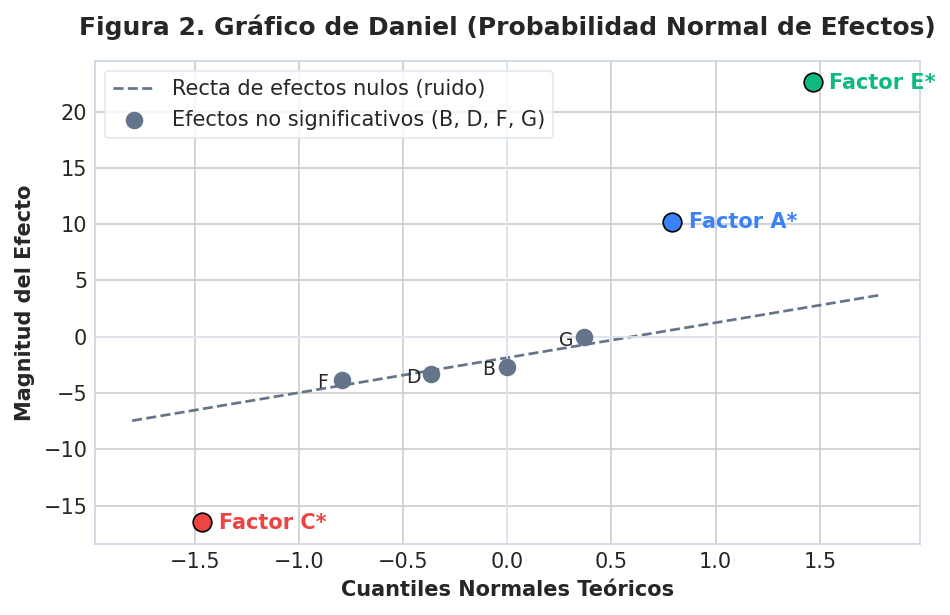

In [ ]:
# Ordenar los 7 efectos para evaluar normalidad frente a cuantiles teóricos
df_daniel = df_effects.sort_values('Efecto').reset_index(drop=True)
m = len(df_daniel)
df_daniel['Rank'] = np.arange(1, m + 1)
df_daniel['Prob'] = (df_daniel['Rank'] - 0.5) / m
df_daniel['Cuantil_Normal'] = stats.norm.ppf(df_daniel['Prob'])

fig, ax = plt.subplots(figsize=(6.5, 4.2), dpi=150)

# Recta de referencia ajustada sobre efectos no significativos (B, D, F, G)
inactivos = df_daniel[~df_daniel['Factor'].isin(['A', 'C', 'E'])]
activos = df_daniel[df_daniel['Factor'].isin(['A', 'C', 'E'])]

slope, intercept = np.polyfit(inactivos['Cuantil_Normal'], inactivos['Efecto'], 1)
x_vals = np.linspace(-1.8, 1.8, 100)
ax.plot(x_vals, slope * x_vals + intercept, '--', color='#64748b', linewidth=1.3, label='Recta de efectos nulos (ruido)')

# Graficar efectos inactivos (sobre la recta)
ax.scatter(inactivos['Cuantil_Normal'], inactivos['Efecto'], color='#64748b', s=55, zorder=3, label='Efectos no significativos (B, D, F, G)')
for _, row in inactivos.iterrows():
    ax.annotate(row['Factor'], (row['Cuantil_Normal'], row['Efecto']), textcoords="offset points", xytext=(-12, -4), fontsize=9)

# Graficar efectos activos (apartados de la recta)
colors_map = {'A': '#3b82f6', 'C': '#ef4444', 'E': '#10b981'}
for _, row in activos.iterrows():
    ax.scatter(row['Cuantil_Normal'], row['Efecto'], color=colors_map[row['Factor']], s=80, zorder=4, edgecolor='black', linewidth=0.8)
    ax.annotate(f"Factor {row['Factor']}*", (row['Cuantil_Normal'], row['Efecto']), textcoords="offset points", xytext=(8, -3),
                fontsize=10, fontweight='bold', color=colors_map[row['Factor']])

ax.axhline(0, color='#e2e8f0', linestyle='-', linewidth=0.8)
ax.axvline(0, color='#e2e8f0', linestyle='-', linewidth=0.8)
ax.set_xlabel('Cuantiles Normales Teóricos', fontsize=10, fontweight='bold')
ax.set_ylabel('Magnitud del Efecto', fontsize=10, fontweight='bold')
ax.set_title('Figura 2. Gráfico de Daniel (Probabilidad Normal de Efectos)', fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#e2e8f0')
plt.tight_layout()
plt.show()

## 7. Visualización 3: Gráficas de Efectos Principales Significativos

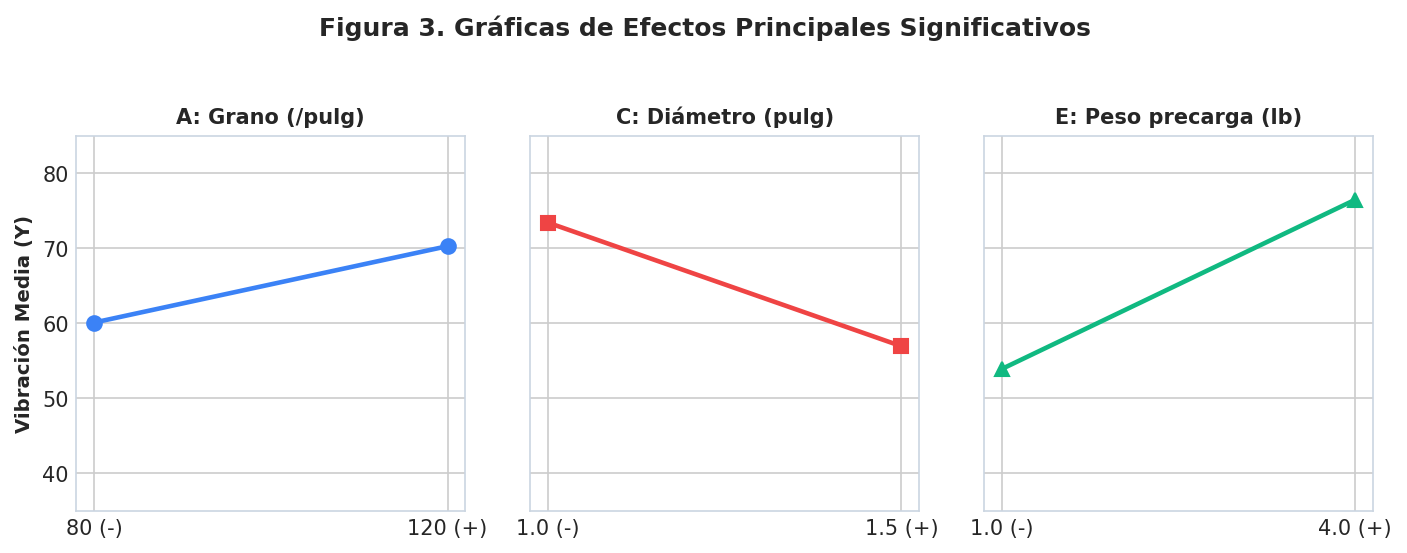

Efecto de A: +10.20 (Mayor grano incrementa vibración)
Efecto de C: -16.50 (Mayor diámetro reduce vibración)
Efecto de E: +22.60 (Mayor precarga incrementa vibración)


In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(9.5, 3.5), dpi=150, sharey=True)

# Medias para A: Grano (80 vs 120)
mean_A_low = df_diseno[df_diseno['A'] == -1]['Vibracion_Y'].mean()
mean_A_high = df_diseno[df_diseno['A'] == 1]['Vibracion_Y'].mean()
ax1.plot([80, 120], [mean_A_low, mean_A_high], 'o-', color='#3b82f6', linewidth=2.2, markersize=7)
ax1.set_title('A: Grano (/pulg)', fontsize=10, fontweight='bold')
ax1.set_xticks([80, 120])
ax1.set_xticklabels(['80 (-)', '120 (+)'])
ax1.set_ylabel('Vibración Media (Y)', fontsize=9.5, fontweight='bold')
ax1.set_ylim(35, 85)

# Medias para C: Diámetro (1.0 vs 1.5)
mean_C_low = df_diseno[df_diseno['C'] == -1]['Vibracion_Y'].mean()
mean_C_high = df_diseno[df_diseno['C'] == 1]['Vibracion_Y'].mean()
ax2.plot([1.0, 1.5], [mean_C_low, mean_C_high], 's-', color='#ef4444', linewidth=2.2, markersize=7)
ax2.set_title('C: Diámetro (pulg)', fontsize=10, fontweight='bold')
ax2.set_xticks([1.0, 1.5])
ax2.set_xticklabels(['1.0 (-)', '1.5 (+)'])

# Medias para E: Peso de precarga (1.0 vs 4.0)
mean_E_low = df_diseno[df_diseno['E'] == -1]['Vibracion_Y'].mean()
mean_E_high = df_diseno[df_diseno['E'] == 1]['Vibracion_Y'].mean()
ax3.plot([1.0, 4.0], [mean_E_low, mean_E_high], '^-', color='#10b981', linewidth=2.2, markersize=7)
ax3.set_title('E: Peso precarga (lb)', fontsize=10, fontweight='bold')
ax3.set_xticks([1.0, 4.0])
ax3.set_xticklabels(['1.0 (-)', '4.0 (+)'])

plt.suptitle('Figura 3. Gráficas de Efectos Principales Significativos', fontsize=12, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

print(f'Efecto de A: {mean_A_high - mean_A_low:+.2f} (Mayor grano incrementa vibración)')
print(f'Efecto de C: {mean_C_high - mean_C_low:+.2f} (Mayor diámetro reduce vibración)')
print(f'Efecto de E: {mean_E_high - mean_E_low:+.2f} (Mayor precarga incrementa vibración)')

## 8. Visualización 4: Gráfico de Cubo y Optimización del Proceso

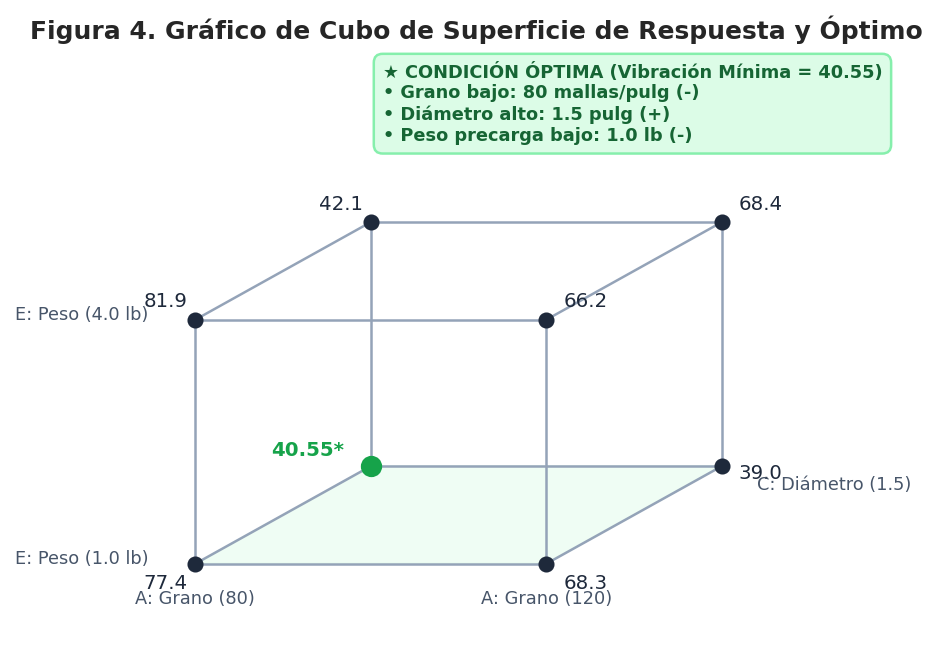

Vibración predicha en el punto óptimo (A=80, C=1.5, E=1.0): 40.55


In [ ]:
# Proyección del cubo factorial para los 3 factores activos (A, C, E)
fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=150)

p1 = (1.0, 1.0)    # A=80, C=1.0, E=1.0
p2 = (4.0, 1.0)    # A=120, C=1.0, E=1.0
p3 = (5.5, 2.2)    # A=120, C=1.5, E=1.0
p4 = (2.5, 2.2)    # A=80, C=1.5, E=1.0 -> CONDICIÓN ÓPTIMA (40.55)

p5 = (1.0, 4.0)    # A=80, C=1.0, E=4.0
p6 = (4.0, 4.0)    # A=120, C=1.0, E=4.0
p7 = (5.5, 5.2)    # A=120, C=1.5, E=4.0
p8 = (2.5, 5.2)    # A=80, C=1.5, E=4.0

edges = [
    (p1, p2), (p2, p3), (p3, p4), (p4, p1),
    (p5, p6), (p6, p7), (p7, p8), (p8, p5),
    (p1, p5), (p2, p6), (p3, p7), (p4, p8)
]

for pt1, pt2 in edges:
    ax.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color='#94a3b8', linestyle='-', linewidth=1.2, zorder=1)

# Sombreado de la cara inferior óptima (E = 1.0 lb)
ax.fill([p1[0], p2[0], p3[0], p4[0]], [p1[1], p2[1], p3[1], p4[1]], color='#dcfce7', alpha=0.45, zorder=0)

nodes = [
    (p1, '77.4', '#1e293b', (-25, -12)),
    (p2, '68.3', '#1e293b', (8, -12)),
    (p3, '39.0', '#1e293b', (8, -6)),
    (p4, '40.55*', '#16a34a', (-48, 5)), # Óptimo predicho
    (p5, '81.9', '#1e293b', (-25, 6)),
    (p6, '66.2', '#1e293b', (8, 6)),
    (p7, '68.4', '#1e293b', (8, 6)),
    (p8, '42.1', '#1e293b', (-25, 6))
]

for pos, val, col, off in nodes:
    size = 85 if col == '#16a34a' else 45
    ax.scatter(pos[0], pos[1], color=col, s=size, zorder=3)
    weight = 'bold' if col == '#16a34a' else 'normal'
    ax.annotate(val, pos, textcoords="offset points", xytext=off, fontsize=9.5, fontweight=weight, color=col)

ax.annotate('A: Grano (80)', (p1[0], p1[1]-0.5), ha='center', fontsize=8.5, color='#475569')
ax.annotate('A: Grano (120)', (p2[0], p2[1]-0.5), ha='center', fontsize=8.5, color='#475569')
ax.annotate('C: Diámetro (1.5)', (p3[0]+0.3, p3[1]-0.3), ha='left', fontsize=8.5, color='#475569')
ax.annotate('E: Peso (4.0 lb)', (p5[0]-0.4, p5[1]), ha='right', fontsize=8.5, color='#475569')
ax.annotate('E: Peso (1.0 lb)', (p1[0]-0.4, p1[1]), ha='right', fontsize=8.5, color='#475569')

# Cuadro destacado de la condición óptima
ax.text(2.6, 6.2, "★ CONDICIÓN ÓPTIMA (Vibración Mínima = 40.55)\n• Grano bajo: 80 mallas/pulg (-)\n• Diámetro alto: 1.5 pulg (+)\n• Peso precarga bajo: 1.0 lb (-)",
        fontsize=8.5, fontweight='bold', color='#166534',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#dcfce7', edgecolor='#86efac', linewidth=1.2))

ax.set_xlim(-0.2, 7.0)
ax.set_ylim(0.0, 7.2)
ax.axis('off')
ax.set_title('Figura 4. Gráfico de Cubo de Superficie de Respuesta y Óptimo', fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

# Verificación matemática de la predicción en el punto óptimo (A=-1, C=+1, E=-1)
y_opt_pred = beta_0 + beta_A*(-1) + beta_C*(1) + beta_E*(-1)
print(f'Vibración predicha en el punto óptimo (A=80, C=1.5, E=1.0): {y_opt_pred:.2f}')

## 9. Matriz Consolidada de Respuestas a las 30 Preguntas del Formulario

In [ ]:
df_respuestas = pd.DataFrame({
    'N°': range(1, 31),
    'Sección / Parte': [
        'Parte 1: Conceptos', 'Parte 1: Conceptos', 'Parte 1: Conceptos', 'Parte 1: Conceptos', 'Parte 1: Conceptos',
        'Parte 2: Resolución', 'Parte 2: Resolución', 'Parte 2: Resolución', 'Parte 2: Resolución', 'Parte 2: Resolución',
        'Parte 3: Alias', 'Parte 3: Alias', 'Parte 3: Alias', 'Parte 3: Alias', 'Parte 3: Alias',
        'Parte 4: Fracciones', 'Parte 4: Fracciones', 'Parte 4: Fracciones', 'Parte 4: Fracciones', 'Parte 4: Fracciones',
        'Parte 5: Análisis', 'Parte 5: Análisis', 'Parte 5: Análisis', 'Parte 5: Análisis', 'Parte 5: Análisis',
        'Parte 6: Conclusiones', 'Parte 6: Conclusiones', 'Parte 6: Conclusiones', 'Parte 6: Conclusiones', 'Parte 6: Conclusiones'
    ],
    'Concepto Evaluado': [
        'Definición y notación 2^(k-p)',
        'Primer factorial con exceso de info (k >= 5: 2^5)',
        'Definición de alias (efectos inseparables)',
        'Ventaja principal: reducción de corridas',
        'Efectos sacrificados preferentemente (orden >= 3)',
        'Característica de Resolución III',
        'Característica de Resolución IV',
        'Característica de Resolución V',
        'Determinación de R en 2^(k-1) por letras del generador',
        'Resolución del diseño de vibración (2^(7-4)_III)',
        'Definición de relación definidora',
        'Número de generadores iniciales (p)',
        'Cálculo de alias de A en I = ABC ([A] = BC)',
        'Multiplicación módulo 2: A x A = I',
        'Efecto principal alias de BC',
        'Paso 1: escribir factorial completo en k - p factores',
        'Paso 2: multiplicar columnas según generadores',
        'Número de corridas: 2^(7-4) = 8',
        'Columna D a partir de I = ABD (D = AB)',
        'Obtención de fracción complementaria (cambiar signos)',
        'Valor de F0 para factor E (61.78)',
        'Significancia de factor A (p = 0.0239 < 0.05)',
        'Grados de libertad del error residual (GL = 4)',
        'Pareto: factores activos A, C y E',
        'Valor del R^2 ajustado (93.71%)',
        'Separación de principal en complementaria: (l1 + l2)/2',
        'Separación de interacción doble: (l1 - l2)/2',
        'Resolución requerida para interacciones: IV o superior',
        'Selección de generadores: tablas / software DOE',
        'Conclusión: 8 corridas bastaron para detectar A, C y E'
    ],
    'Opción': [
        'B', 'C', 'B', 'B', 'C',
        'A', 'B', 'B', 'B', 'A',
        'B', 'B', 'B', 'B', 'A',
        'B', 'B', 'B', 'B', 'B',
        'C', 'B', 'C', 'B', 'C',
        'A', 'B', 'B', 'B', 'B'
    ]
})

print('=== MATRIZ RESUMEN DE RESPUESTAS DEL FORMULARIO ===')
df_respuestas

=== MATRIZ RESUMEN DE RESPUESTAS DEL FORMULARIO ===


,N°,Sección / Parte,Concepto Evaluado,Opción
0,1,Parte 1: Conceptos,Definición y notación 2^(k-p),B
1,2,Parte 1: Conceptos,Primer factorial con exceso de info (k >= 5: 2^5),C
2,3,Parte 1: Conceptos,Definición de alias (efectos inseparables),B
3,4,Parte 1: Conceptos,Ventaja principal: reducción de corridas,B
4,5,Parte 1: Conceptos,Efectos sacrificados preferentemente (orden >= 3),C
5,6,Parte 2: Resolución,Característica de Resolución III,A
6,7,Parte 2: Resolución,Característica de Resolución IV,B
7,8,Parte 2: Resolución,Característica de Resolución V,B
8,9,Parte 2: Resolución,Determinación de R en 2^(k-1) por letras del g...,B
9,10,Parte 2: Resolución,Resolución del diseño de vibración (2^(7-4)_III),A
